<a href="https://colab.research.google.com/github/ummeysalma1110/ml-course/blob/main/MLAssignment01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ummey Salma
email ummey.salma1110@gmail.com

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

Q1 Load the Titanic dataset and display:
Dataset shape
First 10 rows
5 random samples


In [4]:

import pandas as pd

df = pd.read_csv('/content/titanic_data_updated.csv')
print(df.shape)
print(df.head(10))
print(df.sample(5))


(891, 12)
   PassengerId Survived  Pclass  \
0            1       no   third   
1            2      yes   first   
2            3      yes   third   
3            4      yes   first   
4            5       no   third   
5            6       no   third   
6            7       no   first   
7            8       no   third   
8            9      yes   third   
9           10      yes  second   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy J    male  54.

Question 2 (10 Marks)
Perform feature screening on the Titanic dataset by:
Finding total missing values
Finding duplicate rows
Removing duplicate rows permanently


In [5]:


print("Total Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("After Removing Duplicates:", df.shape)


Total Missing Values: 866
Duplicate Rows: 0
After Removing Duplicates: (891, 12)


Question 3 (10 Marks)
Perform statistical profiling of the Titanic dataset and display:
Dataset information
Statistical summary of numerical columns
Also write 2 observations from the output.


In [6]:


# Dataset Information
df.info()

# Statistical Summary of Numerical Columns
print(df.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 83.7+ KB
       PassengerId         Age       SibSp       Parch        Fare
count   891.000000  714.000000  891.000000  891.000000  891.000000
mean    446.000000   29.699118    0.523008    0.381594   32.204208
std     257.353842   14.526497    1.102743 

Question 4 (10 Marks)
Perform univariate categorical analysis on the Survived column by:
Creating a countplot
Calculating percentage distribution
Creating a pie chart
Write 2 insights from the analysis.


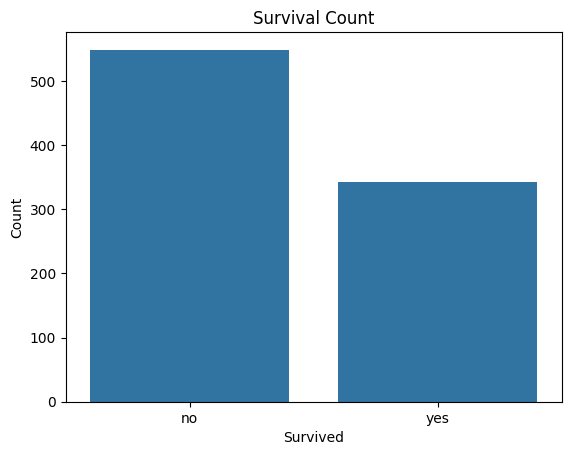

Survived
no     61.616162
yes    38.383838
Name: proportion, dtype: float64


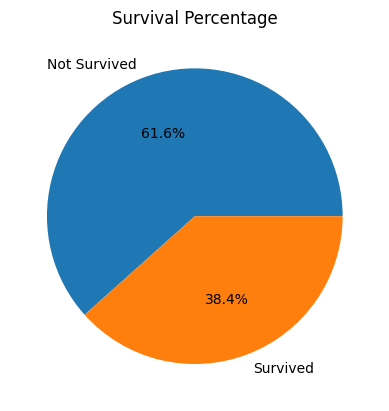

In [7]:


# Countplot
sns.countplot(x='Survived', data=df)
plt.title("Survival Count")
plt.xlabel("Survived")
plt.ylabel("Count")
plt.show()

# Percentage Distribution
print(df['Survived'].value_counts(normalize=True) * 100)

# Pie Chart
df['Survived'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    labels=['Not Survived', 'Survived']
)
plt.title("Survival Percentage")
plt.ylabel("")
plt.show()


Question 5 (10 Marks)
Perform univariate numerical analysis on the Age column by:
Creating a histogram
Creating a KDE plot
Write 2 observations from the plots.


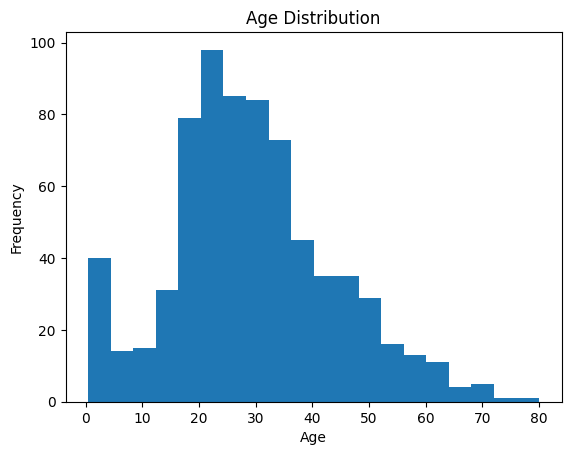

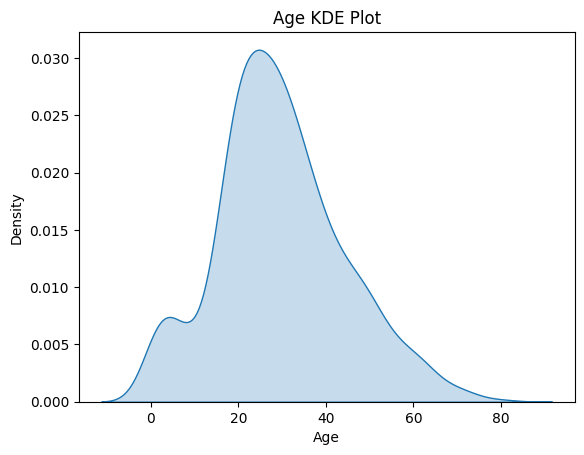

In [8]:

# Histogram
plt.hist(df['Age'].dropna(), bins=20)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# KDE Plot
sns.kdeplot(df['Age'].dropna(), fill=True)
plt.title("Age KDE Plot")
plt.xlabel("Age")
plt.ylabel("Density")
plt.show()


Question 6 (10 Marks)
Perform multivariate analysis between Sex and Survived using a countplot with hue.
Also calculate normalized survival ratios using groupby().
Write 2 insights from the analysis.


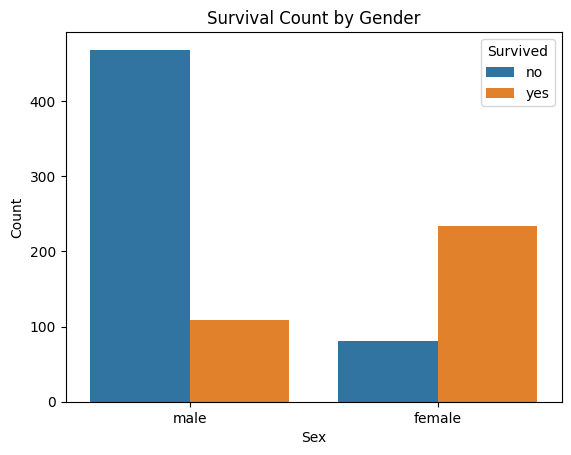

Normalized Survival Ratios:
Sex     Survived
female  yes         0.742038
        no          0.257962
male    no          0.811092
        yes         0.188908
Name: proportion, dtype: float64


In [9]:


# Countplot with Hue
sns.countplot(x='Sex', hue='Survived', data=df)
plt.title("Survival Count by Gender")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()

# Normalized Survival Ratios
print("Normalized Survival Ratios:")
print(df.groupby('Sex')['Survived'].value_counts(normalize=True))


Question 8 (10 Marks)
Create a KDE plot to compare the Age distribution of survived and non-survived passengers.
Write 2 insights from the graph.


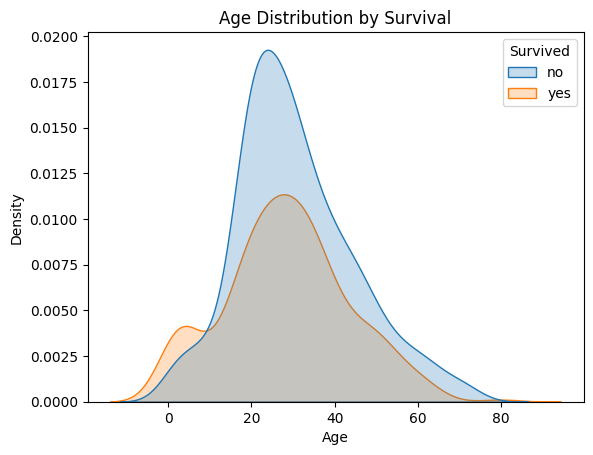

In [10]:


sns.kdeplot(data=df, x='Age', hue='Survived', fill=True)

plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Density")
plt.show()


Question 9 (10 Marks)
Perform feature engineering and train-test split by:
Dropping PassengerId, Name, and Ticket columns
Separating features (X) and target (y)
Splitting the dataset using test_size=0.2 and random_state=42
Display the shapes of train and test datasets.



In [11]:

from sklearn.model_selection import train_test_split


df.drop(['PassengerId', 'Name', 'Ticket'], axis=1, inplace=True)

X = df.drop('Survived', axis=1)
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (712, 8)
X_test shape: (179, 8)
y_train shape: (712,)
y_test shape: (179,)


Question 10 (10 Marks)
Handle missing values in the Titanic dataset by:
Imputing missing Age values using SimpleImputer with mean strategy
Imputing missing Embarked values using most frequent strategy
Imputing missing Cabin values using constant strategy with "Missing"
Finally, check whether any missing values remain.



In [12]:

from sklearn.impute import SimpleImputer

# Age - Mean Strategy
imputer_age = SimpleImputer(strategy='mean')
df[['Age']] = imputer_age.fit_transform(df[['Age']])

# Embarked - Most Frequent Strategy
imputer_embarked = SimpleImputer(strategy='most_frequent')
df[['Embarked']] = imputer_embarked.fit_transform(df[['Embarked']])

# Cabin - Constant Strategy
imputer_cabin = SimpleImputer(strategy='constant', fill_value='Missing')
df[['Cabin']] = imputer_cabin.fit_transform(df[['Cabin']])

# Check Missing Values
print("Missing Values After Imputation:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values After Imputation:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Cabin       0
Embarked    0
dtype: int64

Total Missing Values: 0
